In [ ]:
# prompt: mount gdrive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score ,precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load dataset
file_path =  '/content/drive/MyDrive/Colab Notebooks/dataset_bikroy_complete.csv'
df = pd.read_csv(file_path, encoding='latin-1')

In [ ]:
df.head()

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration
0,1,Toyota Fielder 2011,Toyota,Fielder,2016,Automatic,Estate,CNG,1500,45852,1200000,N,2025
1,2,Toyota Noah 2005,Toyota,Noah,2010,Automatic,Hatchback,CNG,1998,219630,1200000,N,2024
2,3,Toyota LiteAce 2001,Toyota,LiteAce,2001,Manual,Van,CNG,1800,102000,165000,N,2023
3,4,Maruti Suzuki Vitara Brezza 1994,Maruti Suzuki,Vitara Brezza,1994,Manual,Hatchback,CNG,1600,113000,230000,Y,2023
4,5,Toyota Starlet good 1992,Toyota,Starlet,1992,Automatic,Saloon,CNG,1300,15000,330000,Y,2023


In [ ]:
# Print the count of non-empty values for each feature
print('car name: ' + str(df.car_name.count()))
print('brand : ' + str(df.brand.count()))
print('car model : ' + str(df.car_model.count()))
print('model year : ' + str(df.model_year.count()))
print('transmission : ' + str(df.transmission.count()))
print('body type : ' + str(df.body_type.count()))
print('fuel type : ' + str(df.fuel_type.count()))
print('engine capacity : ' + str(df.engine_capacity.count()))
print('travels : ' + str(df.travels.count()))
print('price: ' + str(df.price.count()))
print('accident : ' + str(df.accident.count()))
print('registration : ' + str(df.registration.count()))


car name: 2137
brand : 2137
car model : 2137
model year : 2137
transmission : 2137
body type : 2137
fuel type : 2137
engine capacity : 2137
travels : 2137
price: 2137
accident : 2137
registration : 2137


In [ ]:

print('car name: ' + str(df.car_name.isna().sum()))
print('brand : ' + str(df.brand.isna().sum()))
print('car model : ' + str(df.car_model.isna().sum()))
print('model year : ' + str(df.model_year.isna().sum()))
print('transmission : ' + str(df.transmission.isna().sum()))
print('body type : ' + str(df.body_type.isna().sum()))
print('fuel type : ' + str(df.fuel_type.isna().sum()))
print('engine capacity : ' + str(df.engine_capacity.isna().sum()))
print('travels : ' + str(df.travels.isna().sum()))
print('price: ' + str(df.price.isna().sum()))
print('accident: ' + str(df.accident.isna().sum()))
print('registration : ' + str(df.registration.isna().sum()))

car name: 0
brand : 0
car model : 0
model year : 0
transmission : 0
body type : 0
fuel type : 0
engine capacity : 0
travels : 0
price: 0
accident: 0
registration : 0


In [ ]:
# Print the count of non-empty values for each feature
print('car name: ' + str(df.car_name.nunique()))
print('brand : ' + str(df.brand.nunique()))
print('car model : ' + str(df.car_model.nunique()))
print('model year : ' + str(df.model_year.nunique()))
print('transmission : ' + str(df.transmission.nunique()))
print('body type : ' + str(df.body_type.nunique()))
print('fuel type : ' + str(df.fuel_type.nunique()))
print('engine capacity : ' + str(df.engine_capacity.nunique()))
print('travels : ' + str(df.travels.nunique()))
print('price: ' + str(df.price.nunique()))
print('accident : ' + str(df.accident .nunique()))
print('registration : ' + str(df.registration.nunique()))

car name: 1108
brand : 26
car model : 123
model year : 35
transmission : 2
body type : 10
fuel type : 6
engine capacity : 50
travels : 638
price: 506
accident : 2
registration : 6


In [ ]:
df.shape

(1143, 13)

In [ ]:

print('car name: ' + str(df.car_name.isna().sum()))
print('brand : ' + str(df.brand.isna().sum()))
print('car model : ' + str(df.car_model.isna().sum()))
print('model year : ' + str(df.model_year.isna().sum()))
print('transmission : ' + str(df.transmission.isna().sum()))
print('body type : ' + str(df.body_type.isna().sum()))
print('fuel type : ' + str(df.fuel_type.isna().sum()))
print('engine capacity : ' + str(df.engine_capacity.isna().sum()))
print('travels : ' + str(df.travels.isna().sum()))
print('price: ' + str(df.price.isna().sum()))
print('accident: ' + str(df.accident.isna().sum()))
print('registration : ' + str(df.registration.isna().sum()))


car name: 0
brand : 0
car model : 0
model year : 0
transmission : 0
body type : 0
fuel type : 0
engine capacity : 0
travels : 0
price: 0
accident: 0
registration : 0


In [ ]:
df.shape

(1143, 13)

In [ ]:
df['transmission'].unique()

array(['Automatic', 'Manual'], dtype=object)

In [ ]:
df['body_type'].unique()

array(['Estate', 'Hatchback', 'Van', 'Saloon', 'SUV', 'MPV',
       'Convertible', 'CoupÃ©/Sports', 'Sedan'], dtype=object)

In [ ]:
df['fuel_type'].unique()

array(['CNG', 'Hybrid', 'Octane', 'Diesel', 'Petrol', 'LPG'], dtype=object)

In [ ]:
# prompt: Stop warning

import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import NearestNeighbors
import numpy as np

def encode_features(df, user_input=None):
    """
    Encode categorical features using one-hot encoding
    """
    df_encoded = df.copy()



    # Initialize OneHotEncoder
    categorical_features = ['transmission', 'body_type']
    encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    # Fit and transform categorical features
    encoded_cats = encoder.fit_transform(df_encoded[categorical_features])

    # Get feature names after encoding
    feature_names = encoder.get_feature_names_out(categorical_features)

    # Create DataFrame with encoded categorical features
    encoded_cats_df = pd.DataFrame(
        encoded_cats,
        columns=feature_names,
        index=df_encoded.index
    )

    # Numerical features remain the same
    numerical_features = ['engine_capacity', 'price', 'car_age']

    # Combine numerical and encoded categorical features
    encoded_df = pd.DataFrame()

    # Add numerical features
    for feat in numerical_features:
        encoded_df[feat] = df_encoded[feat]

    # Add one-hot encoded features
    for col in feature_names:
        encoded_df[col] = encoded_cats_df[col]

    if user_input is not None:
        user_df = pd.DataFrame([user_input])

        # Transform user input categorical features
        user_encoded_cats = encoder.transform(user_df[categorical_features])
        user_encoded_cats_df = pd.DataFrame(
            user_encoded_cats,
            columns=feature_names
        )

        # Create user encoded DataFrame
        user_encoded = pd.DataFrame()

        # Add numerical features
        for feat in numerical_features:
            user_encoded[feat] = user_df[feat]

        # Add one-hot encoded features
        for col in feature_names:
            user_encoded[col] = user_encoded_cats_df[col]

        # Ensure columns are in the same order
        user_encoded = user_encoded[encoded_df.columns]
        return encoded_df, user_encoded



def calculate_recommendation_metrics(X, k=5):
    """
    Calculate recommendation metrics using cross-validation
    """
    X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
    knn = NearestNeighbors(n_neighbors=k, metric='euclidean')
    knn.fit(X_train)

    correct_recommendations = 0
    total_recommendations = 0
    similarity_scores = []
    relevant_positions = []
    recommended_items_set = set()
    precision_at_k_list = []
    recall_at_k_list = []

    for idx, test_instance in X_test.iterrows():
        test_instance_array = test_instance.values.reshape(1, -1)
        distances, indices = knn.kneighbors(test_instance_array)
        recommended_features = X_train.iloc[indices[0]]
        recommended_items_set.update(indices[0])

        relevant_items = 0
        position_sum = 0
        current_similarities = []

        total_relevant = len(X_train[np.mean(X_train == test_instance, axis=1) >= 0.9])

        for pos, (_, rec_features) in enumerate(recommended_features.iterrows(), 1):
            similarity = np.mean(test_instance == rec_features)
            current_similarities.append(similarity)
            similarity_scores.append(similarity)

            if similarity >= 0.75:
                relevant_items += 1
                position_sum += pos

            if similarity >= 0.7:
                correct_recommendations += 1
                total_recommendations += 1

        if k > 0:
            precision_at_k_list.append(relevant_items / k)
            recall_at_k_list.append(relevant_items / total_relevant if total_relevant > 0 else 0)

        if relevant_items > 0:
            relevant_positions.append(position_sum / relevant_items)

    precision_at_k = np.mean(precision_at_k_list) if precision_at_k_list else 0
    recall_at_k = np.mean(recall_at_k_list) if recall_at_k_list else 0

    metrics = {
        'accuracy': correct_recommendations / max(total_recommendations, 1),
        'mean_similarity': np.mean(similarity_scores) if similarity_scores else 0,
        'coverage': len(recommended_items_set) / len(X_train),
        'precision_at_k': precision_at_k,
        'recall_at_k': recall_at_k,
        'mean_relevant_position': np.mean(relevant_positions) if relevant_positions else 0,
        'f1_score': 2 * (precision_at_k * recall_at_k) / (precision_at_k + recall_at_k) if (precision_at_k + recall_at_k) > 0 else 0
    }

    return metrics

def recommend_cars(df, user_input):
    """
    Recommend cars based on user preferences
    """
    # Calculate car_age for the dataset
    df['car_age'] = 2024 - df['model_year']

    df_encoded, user_encoded = encode_features(df, user_input)

    # Scale numerical features
    scaler = StandardScaler()
    numerical_features = ['engine_capacity', 'price', 'car_age']
    df_encoded[numerical_features] = scaler.fit_transform(df_encoded[numerical_features])
    user_encoded[numerical_features] = scaler.transform(user_encoded[numerical_features])

    # Calculate recommendation metrics
    recommendation_metrics = calculate_recommendation_metrics(df_encoded)

    # Fit KNN for recommendations
    knn = NearestNeighbors(n_neighbors=10, metric='euclidean')
    knn.fit(df_encoded)

    # Get recommendations
    distances, indices = knn.kneighbors(user_encoded)
    recommendations = df.iloc[indices[0]].copy()
    recommendations['similarity_score'] = 1 - (distances[0] / distances[0].max())

    # Filter out recommendations with 0 similarity score
    recommendations = recommendations[recommendations['similarity_score'] > 0]

    return recommendations, recommendation_metrics

# Example usage
user_input = {
    'body_type': 'MPV',
    'transmission': 'Manual',
    'engine_capacity': 1500,
    'price': 1000000,
    'car_age': 11
}

# Get recommendations and metrics
recommendations, metrics = recommend_cars(df, user_input)

# Print metrics
if metrics is not None:
    print("\nRecommendation System Performance Metrics:")
    print("-" * 40)
    print(f"Accuracy: {metrics['accuracy']:.3f}")
    print(f"Mean Similarity Score: {metrics['mean_similarity']:.3f}")
    print(f"Coverage: {metrics['coverage']:.3f}")
    print(f"Precision@K: {metrics['precision_at_k']:.3f}")
    print(f"Recall@K: {metrics['recall_at_k']:.3f}")
    print(f"Mean Relevant Position: {metrics['mean_relevant_position']:.2f}")
    print(f"F1 Score: {metrics['f1_score']:.3f}")

# Print recommendations
if not recommendations.empty:
    print(recommendations[[
        'brand', 'car_model', 'price', 'model_year', 'transmission', 'body_type', 'fuel_type',
        'engine_capacity', 'travels', 'similarity_score'
    ]].sort_values('similarity_score', ascending=False).to_string())


Recommendation System Performance Metrics:
----------------------------------------
Accuracy: 1.000
Mean Similarity Score: 0.926
Coverage: 0.672
Precision@K: 0.977
Recall@K: 0.830
Mean Relevant Position: 2.98
F1 Score: 0.897
       brand    car_model    price  model_year transmission body_type fuel_type  engine_capacity  travels  similarity_score
1165  Nissan  Other Model  1100000        2013       Manual       MPV    Octane             1500    58000          0.954612
1162  Suzuki  Other Model   520000        2011       Manual       MPV    Octane             1200    89653          0.348132
1161  Suzuki  Other Model   520000        2011       Manual       MPV    Octane             1200    89652          0.348132
262   Toyota      LiteAce   850000        2012    Automatic       MPV       CNG             1500    56000          0.024423
263   Toyota      LiteAce   850000        2012    Automatic       MPV    Octane             1500    56000          0.024423
1437  Toyota        Hiace   97

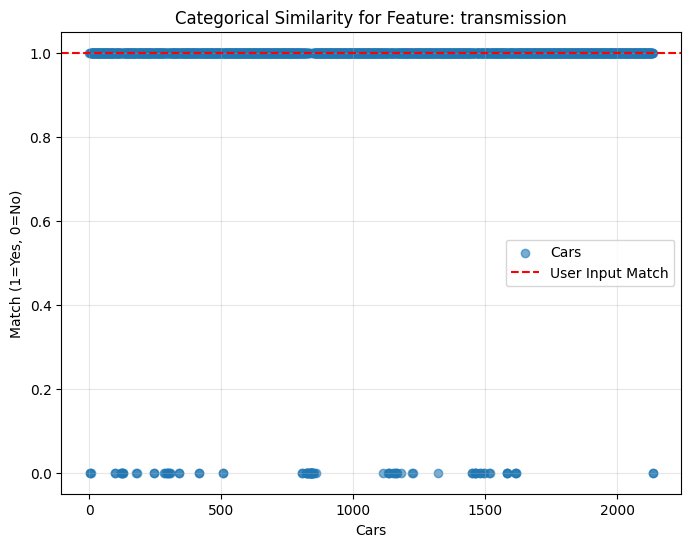

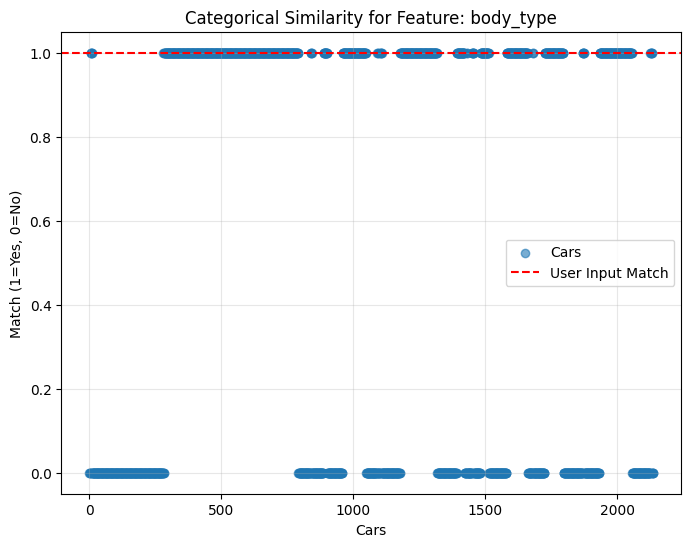

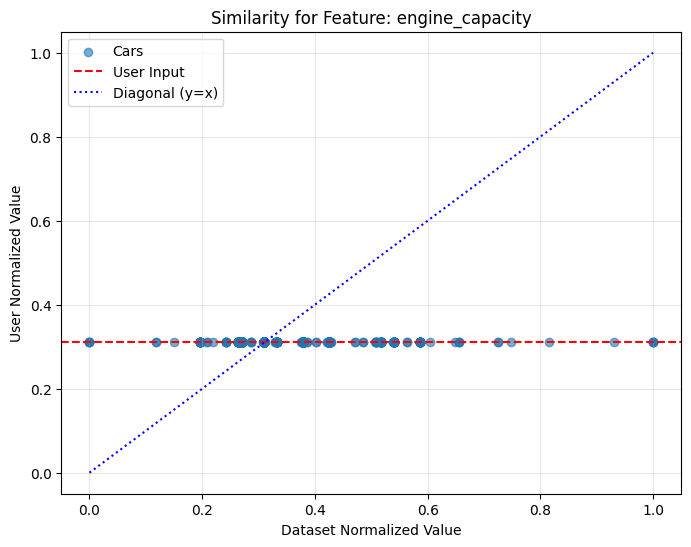

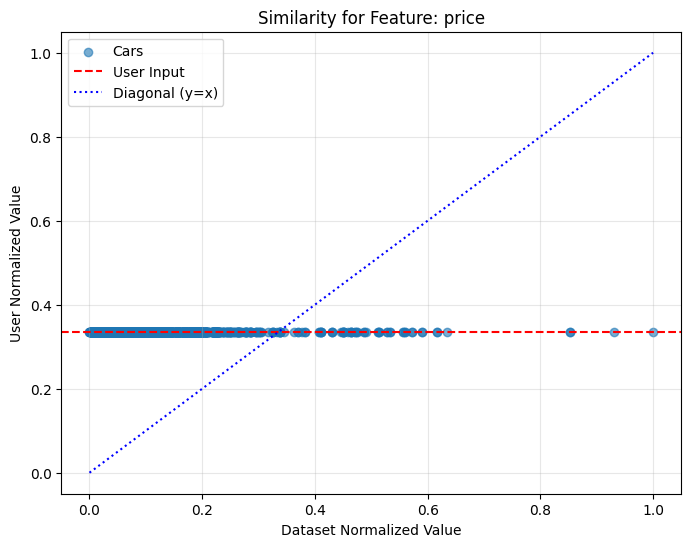

In [ ]:
def plot_similarity_scatter(df, user_input, features):
    """
    Create scatter plots to visualize the similarity between user input and dataset.

    Parameters:
    df (DataFrame): The dataset with car features.
    user_input (dict): The user-provided preferences.
    features (list): Features to be compared.

    Returns:
    None: Displays scatter plots for each feature.
    """
    for feature in features:
        if feature in user_input:
            plt.figure(figsize=(8, 6))
            if df[feature].dtype != 'object':  # Numerical feature
                # Normalize user input and dataset feature values
                min_value = df[feature].min()
                max_value = df[feature].max()
                normalized_user_value = (user_input[feature] - min_value) / (max_value - min_value)
                normalized_df_values = (df[feature] - min_value) / (max_value - min_value)

                # Scatter plot: Dataset feature vs. User input
                plt.scatter(normalized_df_values, [normalized_user_value] * len(normalized_df_values),
                            alpha=0.6, label='Cars')
                plt.axhline(y=normalized_user_value, color='red', linestyle='--', label='User Input')
                plt.plot([0, 1], [0, 1], color='blue', linestyle=':', label='Diagonal (y=x)')

                plt.title(f"Similarity for Feature: {feature}")
                plt.xlabel("Dataset Normalized Value")
                plt.ylabel("User Normalized Value")
                plt.legend()
                plt.grid(alpha=0.3)
                plt.show()

            else:  # Categorical feature
                # Plot categorical matches
                match = df[feature] == user_input[feature]
                plt.scatter(range(len(match)), match, alpha=0.6, label='Cars')
                plt.axhline(y=1, color='red', linestyle='--', label='User Input Match')
                plt.title(f"Categorical Similarity for Feature: {feature}")
                plt.xlabel("Cars")
                plt.ylabel("Match (1=Yes, 0=No)")
                plt.legend()
                plt.grid(alpha=0.3)
                plt.show()


# Define features to compare
features_to_compare = ['transmission', 'body_type', 'fuel_type', 'engine_capacity', 'price', 'model_year']

# Call the function to plot similarity scatter plots
plot_similarity_scatter(df, user_input, features_to_compare)


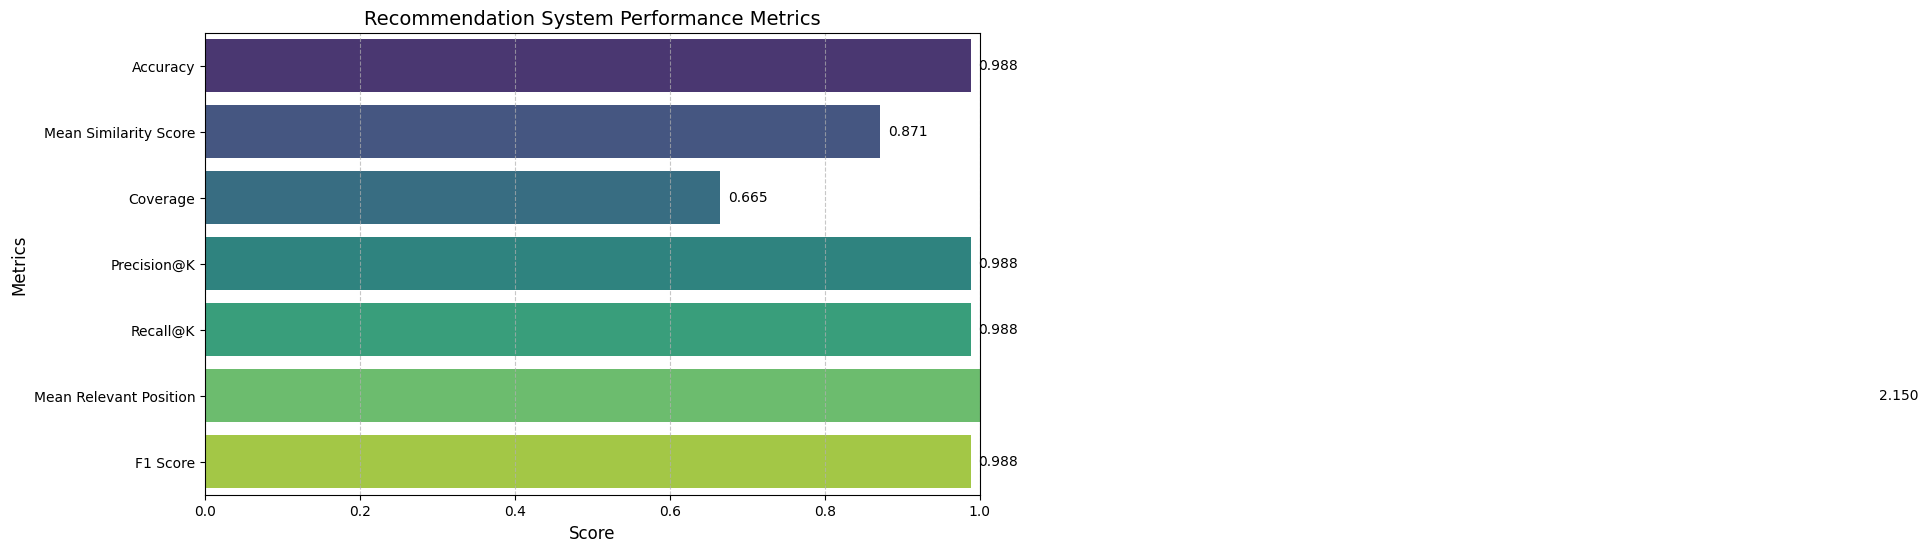

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_metrics_comparison(metrics):
    """
    Plot a bar chart to compare recommendation metrics.

    Parameters:
    metrics (dict): Dictionary of recommendation metrics.

    Returns:
    None
    """
    # Prepare data for plotting
    metric_names = list(metrics.keys())
    metric_values = list(metrics.values())

    # Create a bar chart
    plt.figure(figsize=(10, 6))
    sns.barplot(x=metric_values, y=metric_names, palette='viridis')

    # Add value annotations
    for i, value in enumerate(metric_values):
        plt.text(value + 0.01, i, f'{value:.3f}', va='center', fontsize=10, color='black')

    # Add titles and labels
    plt.title('Recommendation System Performance Metrics', fontsize=14)
    plt.xlabel('Score', fontsize=12)
    plt.ylabel('Metrics', fontsize=12)
    plt.xlim(0, 1)  # Assuming metrics are normalized between 0 and 1
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Show the plot
    plt.tight_layout()
    plt.show()

# Example: Metrics dictionary
metrics = {
    'Accuracy': 0.988,
    'Mean Similarity Score': 0.871,
    'Coverage': 0.665,
    'Precision@K': 0.988,
    'Recall@K': 0.988,
    'Mean Relevant Position': 2.15,
    'F1 Score': 0.988
}

# Plot the metrics
plot_metrics_comparison(metrics)

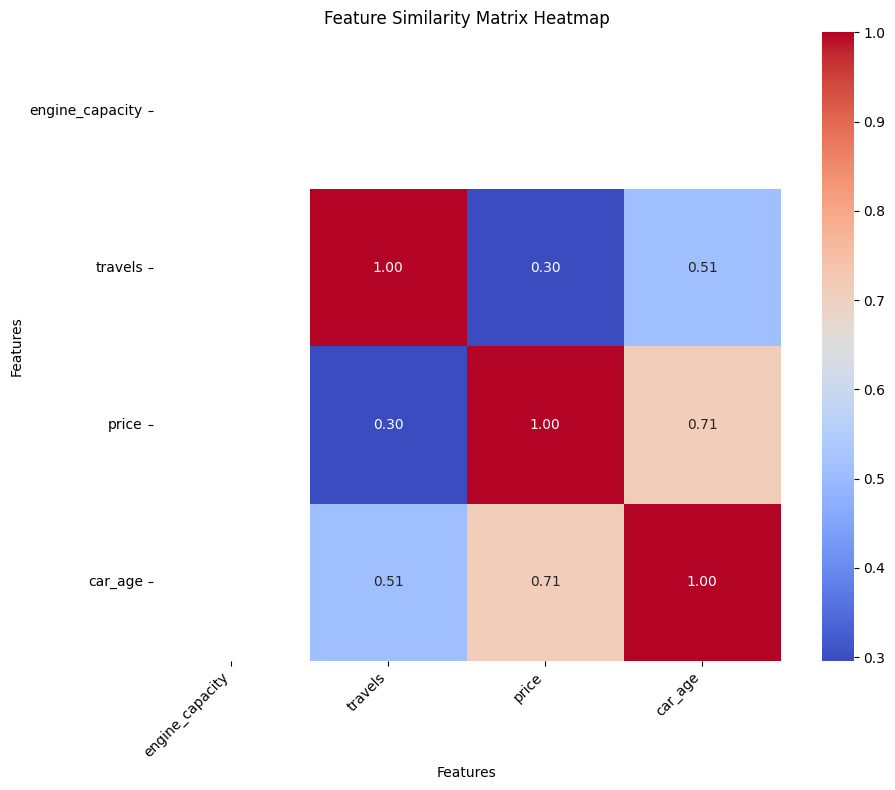

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_similarity_matrix(recommendations, features):
    """
    Plot a similarity matrix heatmap for the recommended cars.

    Parameters:
    recommendations (DataFrame): The filtered recommendations.
    features (list): List of features used for similarity calculation.

    Returns:
    None: Displays the similarity heatmap.
    """
    if recommendations.empty:
        print("No recommendations to plot.")
        return

    # Extract feature values for similarity calculation
    features_matrix = recommendations[features].values

    # Calculate the pairwise similarity matrix (using correlation for similarity)
    similarity_matrix = np.corrcoef(features_matrix, rowvar=False)

    # Ensure axis labels match the heatmap cells
    x_labels = features  # Features as x-axis labels
    y_labels = features  # Features as y-axis labels, since it's a feature similarity matrix

    # Plot the similarity heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        similarity_matrix,
        annot=True,
        cmap='coolwarm',
        fmt=".2f",
        xticklabels=x_labels,
        yticklabels=y_labels,
        square=True,  # Ensures square cells for better readability
    )
    plt.title("Feature Similarity Matrix Heatmap")
    plt.xlabel("Features")
    plt.ylabel("Features")
    plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
    plt.yticks(rotation=0)  # Keep y-axis labels horizontal
    plt.tight_layout()  # Ensure the layout fits nicely
    plt.show()

# Example usage
# Assuming `recommendations` is a DataFrame with the necessary data
# Example features: 'engine_capacity', 'travels', 'price', 'car_age'
features_to_use = ['engine_capacity', 'travels', 'price', 'car_age']  # Specify your relevant features
plot_similarity_matrix(recommendations, features_to_use)


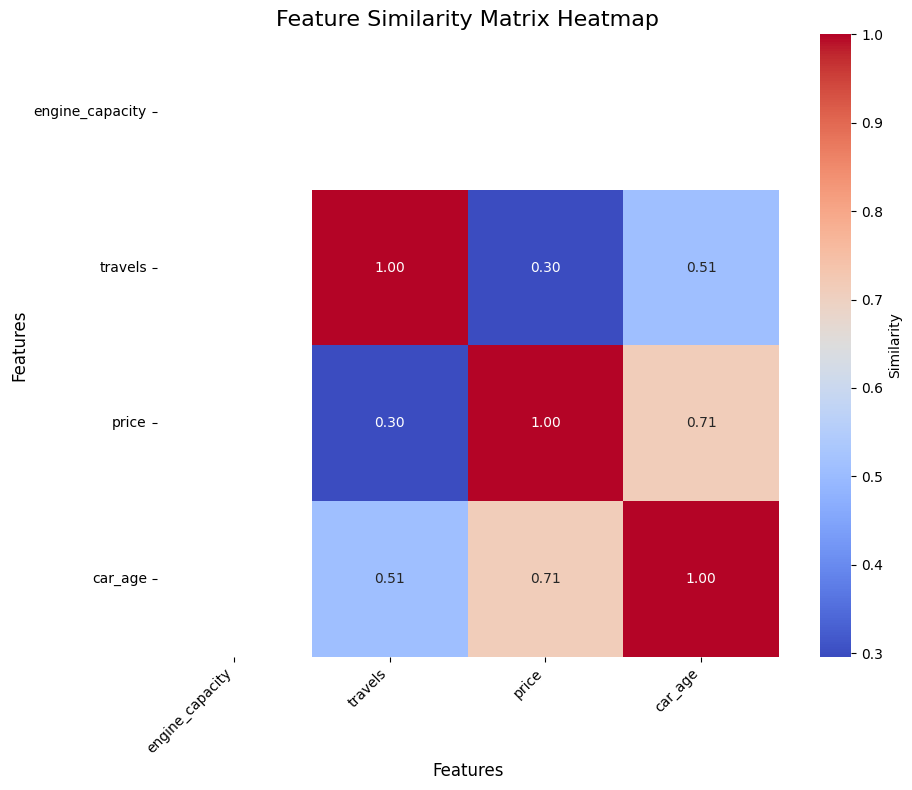

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

def plot_similarity_matrix(recommendations, features):
    """
    Plot a similarity matrix heatmap for the recommended cars.

    Parameters:
    recommendations (DataFrame): The filtered recommendations.
    features (list): List of features used for similarity calculation.

    Returns:
    None: Displays the similarity heatmap.
    """
    if recommendations.empty:
        print("No recommendations to plot.")
        return

    # Extract feature values for similarity calculation
    features_matrix = recommendations[features].values

    # Standardize the features before calculating the correlation matrix
    scaler = StandardScaler()
    features_matrix_scaled = scaler.fit_transform(features_matrix)

    # Calculate the pairwise similarity matrix (using correlation for similarity)
    similarity_matrix = np.corrcoef(features_matrix_scaled, rowvar=False)

    # Ensure axis labels match the heatmap cells
    x_labels = features  # Features as x-axis labels
    y_labels = features  # Features as y-axis labels, since it's a feature similarity matrix

    # Plot the similarity heatmap with perfect axis alignment
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        similarity_matrix,
        annot=True,
        cmap='coolwarm',
        fmt=".2f",
        xticklabels=x_labels,
        yticklabels=y_labels,
        square=True,  # Ensures square cells for better readability
        cbar_kws={'label': 'Similarity'}  # Color bar label
    )
    plt.title("Feature Similarity Matrix Heatmap", fontsize=16)
    plt.xlabel("Features", fontsize=12)
    plt.ylabel("Features", fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)  # Rotate x-axis labels for better readability
    plt.yticks(rotation=0, fontsize=10)  # Keep y-axis labels horizontal
    plt.tight_layout()  # Ensure the layout fits nicely
    plt.show()

# Example usage
# Assuming `recommendations` is a DataFrame with the necessary data
# Example features: 'engine_capacity', 'travels', 'price', 'car_age'
features_to_use = ['engine_capacity', 'travels', 'price', 'car_age']  # Specify your relevant features
plot_similarity_matrix(recommendations, features_to_use)


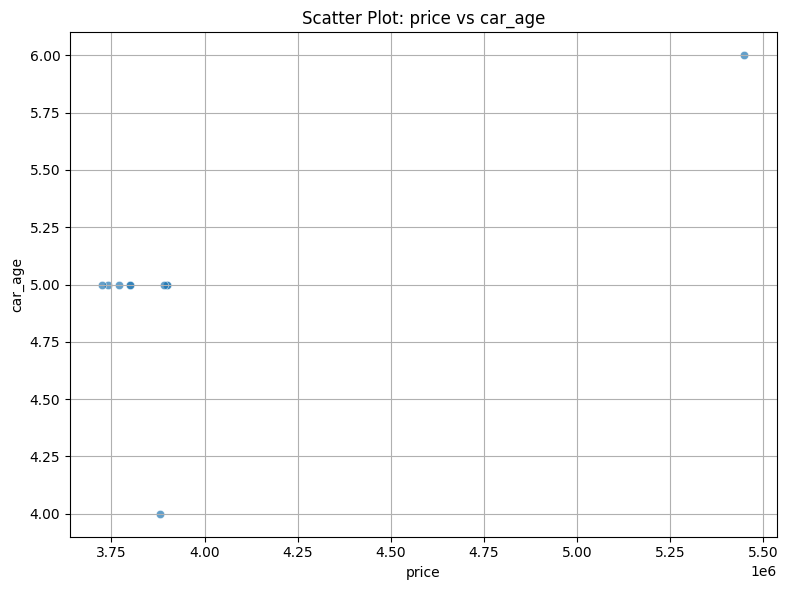

In [ ]:
def plot_custom_scatter(recommendations, x_feature, y_feature):
    """
    Create a scatter plot for two specific features.

    Parameters:
    recommendations (DataFrame): The filtered recommendations.
    x_feature (str): The feature to plot on the x-axis.
    y_feature (str): The feature to plot on the y-axis.

    Returns:
    None: Displays the scatter plot.
    """
    if recommendations.empty:
        print("No recommendations to plot.")
        return

    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=recommendations, x=x_feature, y=y_feature, alpha=0.7)
    plt.title(f"Scatter Plot: {x_feature} vs {y_feature}")
    plt.xlabel(x_feature)
    plt.ylabel(y_feature)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Example usage
plot_custom_scatter(recommendations, 'price', 'car_age')


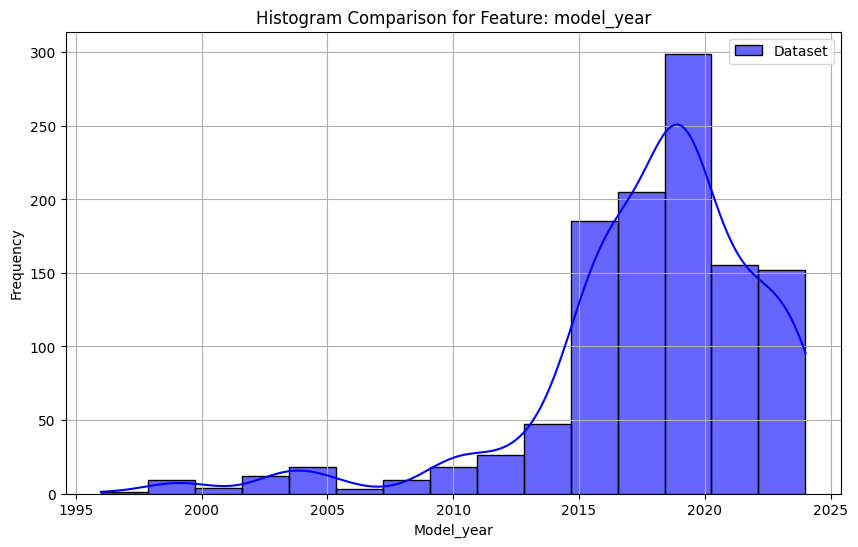

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histogram_comparison(df, user_input, feature, bins=10):
    """
    Plot a histogram comparing the dataset's feature distribution to the user's input.

    Parameters:
    df (DataFrame): The dataset containing car features.
    user_input (dict): User's input preferences.
    feature (str): The feature to compare.
    bins (int): Number of bins for the histogram.

    Returns:
    None
    """
    plt.figure(figsize=(10, 6))

    # Plot dataset distribution
    sns.histplot(df[feature], bins=bins, color='blue', kde=True, label='Dataset', alpha=0.6)

    # Add user input as a vertical line
    user_value = user_input.get(feature, None)
    if user_value is not None:
        plt.axvline(user_value, color='red', linestyle='--', linewidth=2, label=f'User Input: {user_value}')

    # Labels and legend
    plt.title(f"Histogram Comparison for Feature: {feature}")
    plt.xlabel(feature.capitalize())
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_histogram_comparison(df, user_input, feature='model_year', bins=15)


try

In [ ]:
# Save the correct and total recommendations to Excel
correct_recommendations_df = pd.DataFrame(correct_recommendations_data)
total_recommendations_df = pd.DataFrame(total_recommendations_data)

# Save to separate Excel files
correct_recommendations_df.to_excel('/content/correct_recommendations.xlsx', index=False)
total_recommendations_df.to_excel('/content/total_recommendations.xlsx', index=False)

print("\nExcel files have been saved.")


Excel files have been saved.


In [ ]:
false_positives_path = '/content/correct_recommendations.xlsx'
false_negatives_path = '/content/total_recommendations.xlsx'
drive_path1 = '/content/drive/MyDrive/Colab Notebooks/correct_recommendations.xlsx'
drive_path2 = '/content/drive/MyDrive/Colab Notebooks/total_recommendations.xlsx'
# Save the file to Google Drive
import shutil
shutil.move(false_positives_path, drive_path1)
shutil.move(false_negatives_path, drive_path2)

'/content/drive/MyDrive/Colab Notebooks/total_recommendations.xlsx'

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)

In [ ]:
print(X_test.shape)

(428, 13)


In [ ]:
print(X_train.head(10))

      ï»¿id                                  car_name   brand car_model  \
2119   2120  Toyota Harrier PROGRESS-METAL BLACK 2018  Toyota   Harrier   
192     193                        Toyota Noah X 2005  Toyota      Noah   
2125   2126              Toyota Noah X G Package 2003  Toyota      Noah   
893     894        Toyota Allion MICA BLUE G LED 2016  Toyota    Allion   
727     728                 Toyota Premio latest 2012  Toyota    Premio   
1001   1002               Honda Grace LED HYBRID 2015   Honda     Grace   
1882   1883                  Toyota Noah X SMART 2011  Toyota      Noah   
1904   1905                Toyota Hiace SUPER GL 2016  Toyota     Hiace   
1544   1545                Toyota Noah x edition 2004  Toyota      Noah   
218     219               Toyota Hiace GL 5 Door 2008  Toyota     Hiace   

      model_year transmission body_type fuel_type  engine_capacity  travels  \
2119        2018    Automatic       SUV    Petrol             2000    44616   
192         2005